In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

In [39]:
df=pd.read_csv("data_science_job.csv")

In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   enrollee_id             19158 non-null  int64  
 1   city                    19158 non-null  object 
 2   city_development_index  18679 non-null  float64
 3   gender                  14650 non-null  object 
 4   relevent_experience     19158 non-null  object 
 5   enrolled_university     18772 non-null  object 
 6   education_level         18698 non-null  object 
 7   major_discipline        16345 non-null  object 
 8   experience              19093 non-null  float64
 9   company_size            13220 non-null  object 
 10  company_type            13018 non-null  object 
 11  training_hours          18392 non-null  float64
 12  target                  19158 non-null  float64
dtypes: float64(4), int64(1), object(8)
memory usage: 1.9+ MB


In [41]:
df.head()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,20.0,NaN,NaN,36.0,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15.0,50-99,Pvt Ltd,47.0,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5.0,NaN,NaN,83.0,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,0.0,NaN,Pvt Ltd,52.0,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,20.0,50-99,Funded Startup,8.0,0.0


In [42]:
df.isnull().sum()

enrollee_id                  0
city                         0
city_development_index     479
gender                    4508
relevent_experience          0
enrolled_university        386
education_level            460
major_discipline          2813
experience                  65
company_size              5938
company_type              6140
training_hours             766
target                       0
dtype: int64

In [43]:
(df.isnull().mean()*100).round(3)

enrollee_id                0.000
city                       0.000
city_development_index     2.500
gender                    23.531
relevent_experience        0.000
enrolled_university        2.015
education_level            2.401
major_discipline          14.683
experience                 0.339
company_size              30.995
company_type              32.049
training_hours             3.998
target                     0.000
dtype: float64

In [44]:
cols=[var for var in df.columns if df[var].isnull().mean()<0.05 and df[var].isnull().mean()>0]
cols

['city_development_index',
 'enrolled_university',
 'education_level',
 'experience',
 'training_hours']

### This helps to extract features with minimum mising values which is less than than 5%

In [45]:
len(df[cols].dropna())/len(df)

0.8968577095730244

### This tells that we have 89 percent of data remaining

In [46]:
df_new=df[cols].dropna()

In [47]:
df_new.isnull().sum()

city_development_index    0
enrolled_university       0
education_level           0
experience                0
training_hours            0
dtype: int64

array([[<Axes: title={'center': 'city_development_index'}>,
        <Axes: title={'center': 'experience'}>],
       [<Axes: title={'center': 'training_hours'}>, <Axes: >]],
      dtype=object)

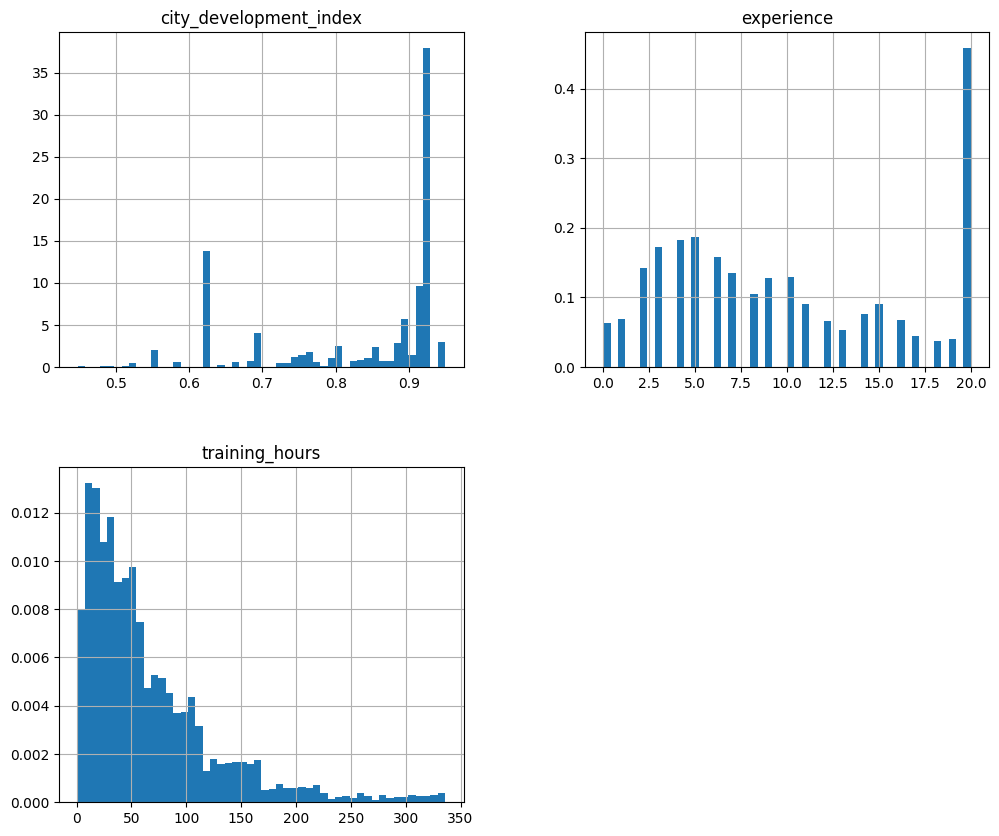

In [48]:
df_new.hist(bins=50,density=True,figsize=(12,10))

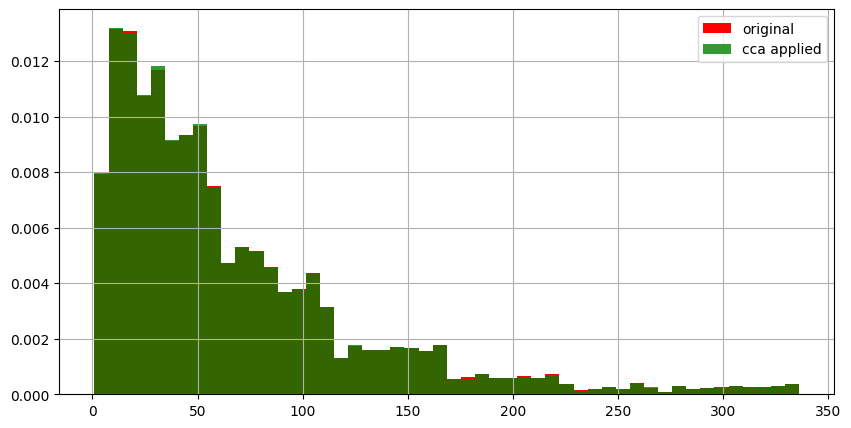

In [86]:
fig = plt.figure(figsize=(10,5))
ax = fig.add_subplot(111)
df["training_hours"].hist(bins=50,ax=ax,density=True,color="red",label="original")
# alpha is used for make color transperency, so we can see  overlay of 2 distribution 
df_new["training_hours"].hist(bins=50,ax=ax,density=True,color="green",alpha=0.8,label="cca applied")
ax.legend()
plt.show()

<Axes: ylabel='Density'>

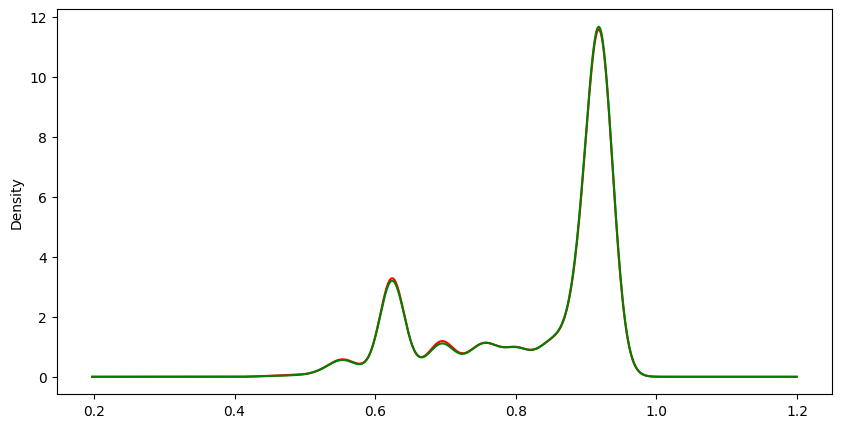

In [88]:
fig = plt.figure(figsize=(10,5))
ax = fig.add_subplot(111)
df["city_development_index"].plot.density(color="red")
df_new["city_development_index"].plot.density(color="green")

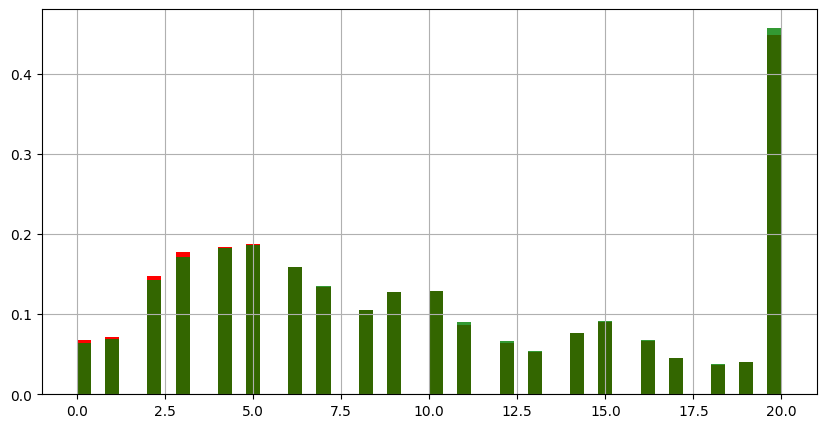

In [91]:
fig = plt.figure(figsize=(10,5))
ax = fig.add_subplot(111)
df["experience"].hist(bins=50,ax=ax,density=True,color="red")
df_new["experience"].hist(bins=50,ax=ax,density=True,color="green",alpha=0.8)
plt.show()

### As we can see that  the distribution is same as original after apllying cca

In [92]:
df["education_level"].value_counts()

education_level
Graduate          11598
Masters            4361
High School        2017
Phd                 414
Primary School      308
Name: count, dtype: int64

In [99]:
temp=pd.concat([
    # % of a observation per category original data 
    df["education_level"].value_counts()/len(df),
    # % of a observation per category cca data 
    df_new["education_level"].value_counts()/len(df)
    ],axis=1
)
temp.columns=["original","cca"]

In [100]:
temp

,original,cca
education_level,,
Graduate,0.605387,0.555904
Masters,0.227633,0.209938
High School,0.105282,0.096304
Phd,0.021610,0.019835
Primary School,0.016077,0.014876


In [101]:
temp=pd.concat([
    # % of a observation per category original data 
    df["enrolled_university"].value_counts()/len(df),
    # % of a observation per category cca data 
    df_new["enrolled_university"].value_counts()/len(df)
    ],axis=1
)
temp.columns=["original","cca"]

In [102]:
temp

,original,cca
enrolled_university,,
no_enrollment,0.721213,0.659359
Full time course,0.196106,0.180029
Part time course,0.062533,0.057469


### So basically we see here we can check the ration of categorical column and compare weather there is drastic change is there in data or not we can do this for many types of columns